In [1]:
# 1. Загрузите изображение в оттенках серого sar_1_gray.jpg. 
# 2. постройте гистограмму
# 3. реализуйте алгоритм гамма коррекции с параметром гамма <1, >1.
# 4. Сравните исходное изображение, скорректированное при помощи гамма-фильтра. MSE, SSIM.
# 5. реализуйте алгоритм статистической цветокоррекции на основе статистики eq_gray.
# 6. Протестируйте работу алгоритмов пороговой фильтрации с различными параметрами.
# Для каждого решения - напечатайте результат

In [2]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity, mean_squared_error

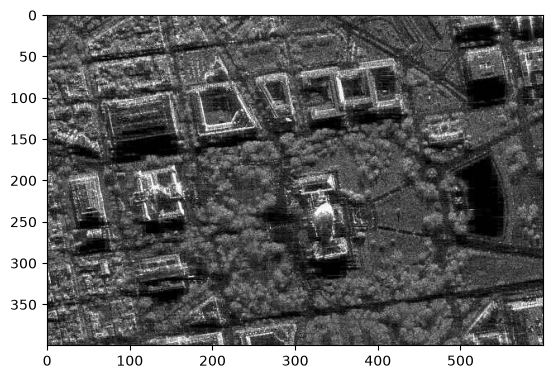

In [3]:
## Пункт 1. Загрузка изображения в оттенках серого
gray_image = cv2.imread('sar_1_gray.jpg', cv2.IMREAD_GRAYSCALE)
plt.imshow(gray_image, cmap='gray')

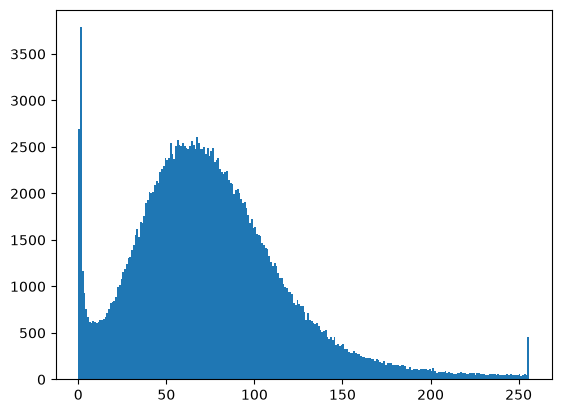

In [4]:
## Пункт 2. Построение гистограммы
plt.hist(gray_image.ravel(), bins=256, range=(0, 256))
plt.show()

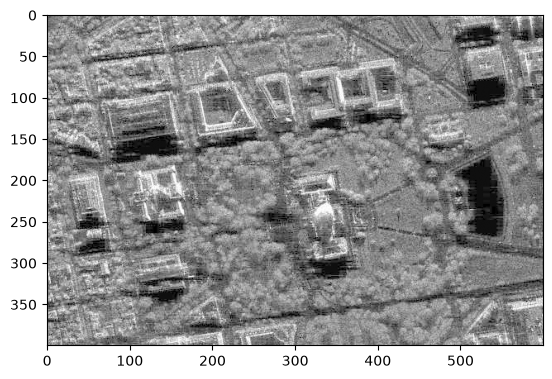

In [5]:
## Пункт 3. Гамма-коррекция изображения
## Гамма-коррекция при gamma < 1
gamma = 0.5

gamma_corrected_05 = np.array(
    255 * (gray_image / 255) ** gamma,
    dtype='uint8'
)

plt.imshow(gamma_corrected_05, cmap='gray')
plt.show()

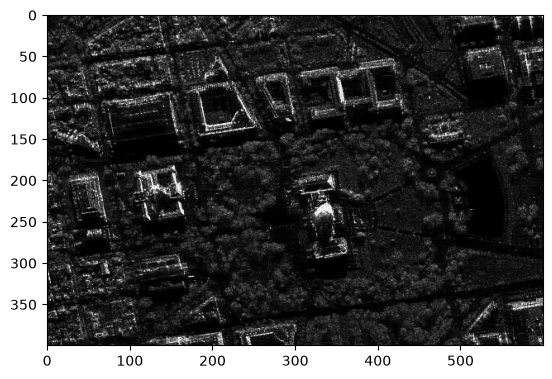

In [6]:
## Гамма-коррекция при gamma > 1
gamma = 2.0

gamma_corrected_20 = np.array(
    255 * (gray_image / 255) ** gamma,
    dtype='uint8'
)

plt.imshow(gamma_corrected_20, cmap='gray')
plt.show()

In [7]:
## Пункт 4. Сравнение изображений по MSE и SSIM
mse_05 = mean_squared_error(gray_image, gamma_corrected_05)
ssim_05 = structural_similarity(gray_image, gamma_corrected_05)

mse_20 = mean_squared_error(gray_image, gamma_corrected_20)
ssim_20 = structural_similarity(gray_image, gamma_corrected_20)

print("Gamma = 0.5")
print("MSE:", mse_05)
print("SSIM:", ssim_05)

print()

print("Gamma = 2.0")
print("MSE:", mse_20)
print("SSIM:", ssim_20)

Gamma = 0.5
MSE: 3250.429145833333
SSIM: 0.7875008686792752

Gamma = 2.0
MSE: 2383.7636375
SSIM: 0.5270459922820343


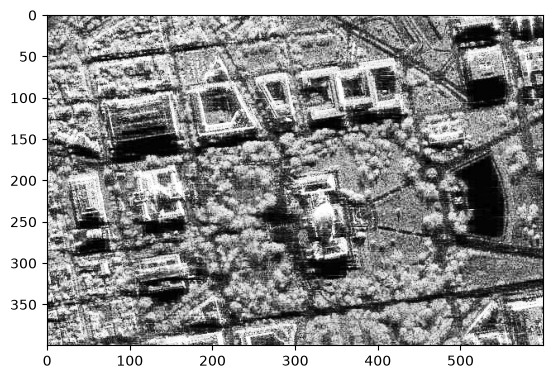

In [8]:
## Собственная реализация эквализации гистограммы

hist = np.zeros(256, dtype=np.int64)

for pixel in gray_image.ravel():
    hist[pixel] += 1

cdf = hist.cumsum()

cdf_min = cdf[cdf > 0][0]
total_pixels = gray_image.size

lookup_table = np.round(
    (cdf - cdf_min) / (total_pixels - cdf_min) * 255
)

lookup_table = np.clip(lookup_table, 0, 255).astype(np.uint8)

equalized_manual = lookup_table[gray_image]

plt.imshow(equalized_manual, cmap='gray')
plt.show()

eq_gray = equalized_manual

In [9]:
## Пункт 5. Статистическая коррекция изображения
mean_gray = gray_image.mean()
std_gray = gray_image.std()

mean_eq = eq_gray.mean()
std_eq = eq_gray.std()

print("gray_image:")
print("Среднее:", mean_gray)
print("Стандартное отклонение:", std_gray)

print()

print("eq_gray:")
print("Среднее:", mean_eq)
print("Стандартное отклонение:", std_eq)

gray_image:
Среднее: 74.94157083333333
Стандартное отклонение: 43.658465466227916

eq_gray:
Среднее: 127.02563333333333
Стандартное отклонение: 74.26964841889017


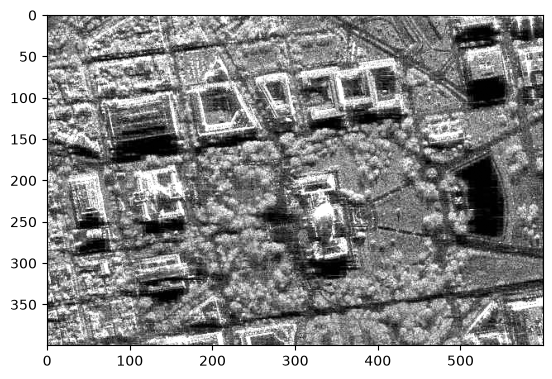

In [10]:
corrected = (
    (gray_image.astype(np.float32) - mean_gray)
    * (std_eq / std_gray)
    + mean_eq
)

corrected = np.clip(corrected, 0, 255).astype(np.uint8)

plt.imshow(corrected, cmap='gray')
plt.show()

In [11]:
print("Скорректированное изображение:")
print("Среднее:", corrected.mean())
print("Стандартное отклонение:", corrected.std())

Скорректированное изображение:
Среднее: 123.1181375
Стандартное отклонение: 65.3025763098039


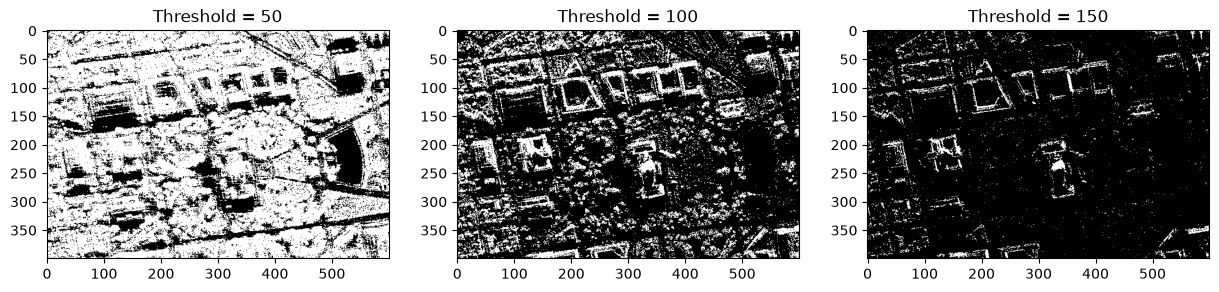

In [12]:
## Пункт 6. Пороговая фильтрация
_, thresh_50 = cv2.threshold(gray_image, 50, 255, cv2.THRESH_BINARY)
_, thresh_100 = cv2.threshold(gray_image, 100, 255, cv2.THRESH_BINARY)
_, thresh_150 = cv2.threshold(gray_image, 150, 255, cv2.THRESH_BINARY)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(thresh_50, cmap='gray')
plt.title('Threshold = 50')

plt.subplot(1, 3, 2)
plt.imshow(thresh_100, cmap='gray')
plt.title('Threshold = 100')

plt.subplot(1, 3, 3)
plt.imshow(thresh_150, cmap='gray')
plt.title('Threshold = 150')

plt.show()